# CSC2042S
## Artificial Neural Networks

This Notebook explores understanding basic neural network structures.

In [ ]:
# Setup — run this first
!pip install -q torch torchvision scikit-learn tensorflow matplotlib numpy

import numpy as np
import matplotlib.pyplot as plt
np.random.seed(42)
print("Setup complete.")

Setup complete.


In [ ]:
# ==============================================================================
# CELL 1 [CODE]: Environment Setup & Library Imports
# ==============================================================================
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Set deterministic seed for reproducibility
np.random.seed(42)
torch.manual_seed(42)

print(f"NumPy Version: {np.__version__}")
print(f"PyTorch Version: {torch.__version__}")

NumPy Version: 2.1.3
PyTorch Version: 2.11.0+cpu


## Recap: Activation functions

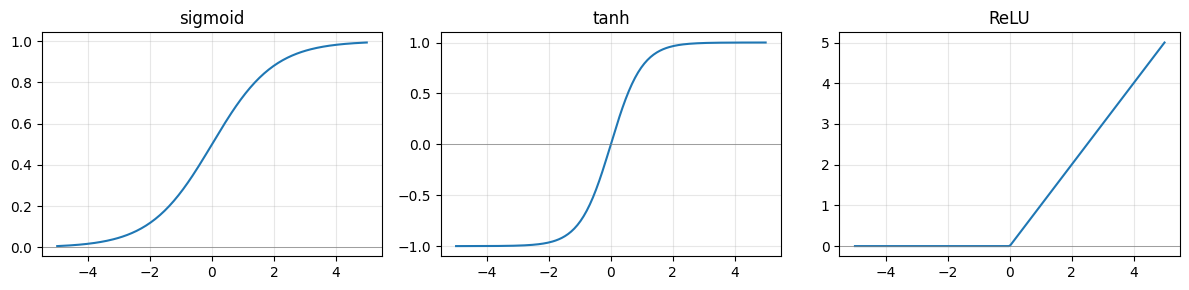

softmax of [2, 1, 0.1] -> [0.65900114 0.24243297 0.09856589]  (sums to 1.0 )


In [ ]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def tanh(z):
    return np.tanh(z)

def relu(z):
    return np.maximum(0, z)

def softmax(z):
    z_shifted = z - np.max(z, axis=-1, keepdims=True)
    exp_z = np.exp(z_shifted)
    return exp_z / np.sum(exp_z, axis=-1, keepdims=True)

# Quick visual sanity check
z = np.linspace(-5, 5, 200)
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
ax[0].plot(z, sigmoid(z)); ax[0].set_title("sigmoid")
ax[1].plot(z, tanh(z));    ax[1].set_title("tanh")
ax[2].plot(z, relu(z));    ax[2].set_title("ReLU")
for a in ax: a.axhline(0, color='gray', lw=0.5); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print("softmax of [2, 1, 0.1] ->", softmax(np.array([2.0, 1.0, 0.1])), " (sums to", softmax(np.array([2.0,1.0,0.1])).sum(), ")")


## From a neuron to a network
A single neuron computes $a = g(w^Tx + b)$ — one dot product, one activation. A **network** just stacks many of these into **layers**, and stacks layers on top of each other.

**Notation we'll use (standard in most textbooks):**

- $L$ = number of layers (not counting the input)
- $n^{[l]}$ = number of neurons in layer $l$
- $W^{[l]}$ = weight matrix for layer $l$, shape $(n^{[l]}, n^{[l-1]})$
- $b^{[l]}$ = bias vector for layer $l$, shape $(n^{[l]}, 1)$
- $z^{[l]} = W^{[l]} a^{[l-1]} + b^{[l]}$ — the pre-activation ("logits" for the last layer)
- $a^{[l]} = g^{[l]}(z^{[l]})$ — the activation, with $a^{[0]} = x$ (the input)

**The one thing that trips people up:** the shape of $W^{[l]}$ is $(\text{neurons in this layer}, \text{neurons in previous layer})$ — it maps *from* the previous layer's size *to* this layer's size. Getting this transposed is the single most common bug when building a network by hand.

A full forward pass is just this equation applied layer by layer, $l = 1, 2, \dots, L$:

$$x \;\rightarrow\; z^{[1]}=W^{[1]}x+b^{[1]} \;\rightarrow\; a^{[1]}=g^{[1]}(z^{[1]}) \;\rightarrow\; z^{[2]}=W^{[2]}a^{[1]}+b^{[2]} \;\rightarrow\; a^{[2]}=g^{[2]}(z^{[2]}) \;\rightarrow\; \dots \;\rightarrow\; \hat{y}=a^{[L]}$$


## Building a network
We'll build a small **2-layer network** (1 hidden layer + 1 output layer):

- Input layer: $n^{[0]} = 4$ features
- Hidden layer: $n^{[1]} = 5$ neurons, ReLU activation
- Output layer: $n^{[2]} = 3$ neurons, softmax activation (a 3-class classification problem)

**Exercise: ** — write `initialize_parameters`, which creates $W^{[1]}, b^{[1]}, W^{[2]}, b^{[2]}$ with the correct shapes. Use small random weights (`* 0.01`) and zero biases — this is standard practice: it breaks symmetry between neurons without exploding early activations.


In [ ]:
# Exercise: initialise parameters for a network with the given layer sizes
def initialize_parameters(layer_dims):
    '''
    layer_dims: list like [4, 5, 3] meaning n_input=4, n_hidden=5, n_output=3
    Returns a dict of parameters: W1, b1, W2, b2, ...
    '''
    params = {}
    L = len(layer_dims) - 1  # number of layers with weights
    for l in range(1, L + 1):
        # TODO: create params[f"W{l}"] with shape (layer_dims[l], layer_dims[l-1])
        # TODO: create params[f"b{l}"] with shape (layer_dims[l], 1), initialised to zero
        pass
    return params

In [ ]:
# Solution
def initialize_parameters(layer_dims):
    params = {}
    L = len(layer_dims) - 1
    for l in range(1, L + 1):
        params[f"W{l}"] = np.random.randn(layer_dims[l], layer_dims[l-1]) * 0.01
        params[f"b{l}"] = np.zeros((layer_dims[l], 1))
    return params

params = initialize_parameters([4, 5, 3])
for k, v in params.items():
    print(k, v.shape)


W1 (5, 4)
b1 (5, 1)
W2 (3, 5)
b2 (3, 1)


In [ ]:
import numpy as np
layer_dims = [4, 5, 3]
params = {}
L = len(layer_dims) - 1
# for l in range(1, L + 1):
l = 1
params[f"W{l}"] = np.random.randn(layer_dims[l], layer_dims[l-1]) * 0.01
params[f"W{l}"]

array([[-0.01165219, -0.00084553,  0.01050588, -0.00316911],
       [ 0.00176387, -0.02451936,  0.01272054,  0.01237687],
       [-0.00362823,  0.01348029,  0.01157785, -0.00057294],
       [-0.00725669,  0.00631302,  0.00265874,  0.01203555],
       [-0.00283693,  0.01082985, -0.00216281,  0.01199176]])

**Exercise:** — write `forward_propagation`, which takes an input `X` (shape `(n_features, n_examples)` — features as rows, examples as columns, matching the $W^{[l]}a^{[l-1]}$ convention above) and the `params` dict, and returns the final output plus a `cache` of every intermediate `z` and `a`.

In [ ]:
# Exercise: implement the full forward pass for our 2-layer network
def forward_propagation(X, params):
    '''
    X: shape (n_features, n_examples)
    Returns: (y_hat, cache) where y_hat is the network's output (n_output, n_examples)
    '''
    cache = {"A0": X}

    # TODO: z1 = W1 @ X + b1 ;  a1 = relu(z1)
    # TODO: z2 = W2 @ a1 + b2 ;  a2 = softmax(z2.T).T   <-- careful: softmax as written above
    #        expects examples as ROWS, so transpose in/out, or write a column-wise softmax.
    # store every z and a into cache, e.g. cache["Z1"] = z1, cache["A1"] = a1, etc.

    y_hat = None
    return y_hat, cache


In [ ]:
# Solution
def softmax_columns(z):
    # column-wise softmax: each COLUMN is one example, shape (n_classes, n_examples)
    z_shifted = z - np.max(z, axis=0, keepdims=True)
    exp_z = np.exp(z_shifted)
    return exp_z / np.sum(exp_z, axis=0, keepdims=True)

def forward_propagation(X, params):
    cache = {"A0": X}
    L = len(params) // 2  # each layer contributes a W and a b

    A = X
    for l in range(1, L + 1):
        W, b = params[f"W{l}"], params[f"b{l}"]
        Z = W @ A + b
        if l == L:
            A = softmax_columns(Z)   # output layer -> softmax
        else:
            A = relu(Z)              # hidden layers -> ReLU
        cache[f"Z{l}"] = Z
        cache[f"A{l}"] = A

    y_hat = A
    return y_hat, cache

# Sanity check on 4 features, 6 examples
X_toy = np.random.randn(4, 6)
params = initialize_parameters([4, 5, 3])
y_hat, cache = forward_propagation(X_toy, params)
print("y_hat shape:", y_hat.shape, " (should be (3, 6): 3 classes x 6 examples)")
print("Each column sums to 1 (a probability distribution):", y_hat.sum(axis=0))

Talking point for class: notice we never used the label  𝑦
  anywhere in forward_propagation — forward propagation only produces a prediction. Turning that prediction into a trained network needs a loss function and backpropagation, which is next session's topic. Everything from here is about wiring the calculation correctly, not yet about learning.

## Running it on real data: MNIST

Same network, same code — now on real handwritten digit images. We'll use a **small subset** (1,000 training images, 200 test images) rather than the full 70,000-image MNIST.

 Each MNIST image is 28×28 = **784 pixels**, so our input layer needs $n^{[0]}=784$. There are 10 digit classes (0–9), so $n^{[L]}=10$.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Raw image shape: (1000, 28, 28)


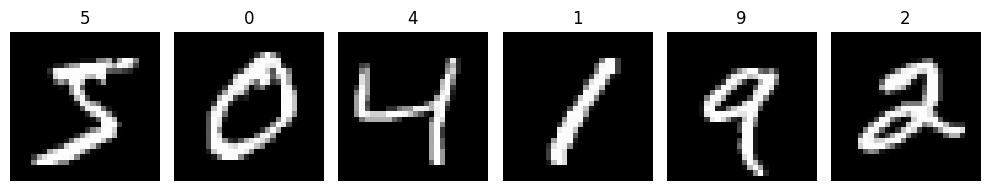

In [ ]:
# Load MNIST and take a small subset
from tensorflow.keras.datasets import mnist

(X_train_full, y_train_full), (X_test_full, y_test_full) = mnist.load_data()

n_train, n_test = 1000, 200
X_train_raw, y_train = X_train_full[:n_train], y_train_full[:n_train]
X_test_raw, y_test = X_test_full[:n_test], y_test_full[:n_test]

print("Raw image shape:", X_train_raw.shape)  # (1000, 28, 28)

# Peek at a few digits
fig, axes = plt.subplots(1, 6, figsize=(10, 2))
for i, ax in enumerate(axes):
    ax.imshow(X_train_raw[i], cmap="gray"); ax.set_title(str(y_train[i])); ax.axis("off")
plt.tight_layout(); plt.show()

**Exercise**
Preprocess the data so it matches what forward_propagation expects:

Flatten each 28×28 image into a 784-length vector.
Scale pixel values from [0, 255] to [0, 1] (networks train/behave much better on small, normalised inputs).
Arrange as (n_features, n_examples) — i.e. features as rows, examples as columns (the transpose of how the data naturally comes out of .reshape).

In [ ]:
# Exercise: preprocess X_train_raw / X_test_raw into (784, n_examples), scaled to [0,1]
def preprocess(X_raw):
    # TODO
    pass

X_train = preprocess(X_train_raw)
X_test = preprocess(X_test_raw)
print(X_train.shape, X_test.shape)  # should be (784, 1000) (784, 200)


In [ ]:
# Solution
def preprocess(X_raw):
    n_examples = X_raw.shape[0]
    X_flat = X_raw.reshape(n_examples, -1)   # (n_examples, 784)
    X_norm = X_flat.astype("float32") / 255.0
    return X_norm.T                          # (784, n_examples)

X_train = preprocess(X_train_raw)
X_test = preprocess(X_test_raw)
print(X_train.shape, X_test.shape)



**Exercise** — build a network with architecture `[784, 64, 10]` (one hidden layer of 64 neurons), run a forward pass over the training subset, and report the accuracy. It will be close to **10% (random chance)** — the weights are random and nobody has trained anything yet. That "bad but plausible" number is itself the teaching point: forward propagation alone gives you *a* prediction, not a *good* one.


In [ ]:
# Exercise 3: build [784, 64, 10], run forward pass, compute accuracy
# TODO: params = initialize_parameters([784, 64, 10])
# TODO: y_hat, _ = forward_propagation(X_train, params)
# TODO: predictions = argmax over the class axis of y_hat
# TODO: accuracy = mean(predictions == y_train)

In [ ]:
# Solution
params = initialize_parameters([784, 64, 10])
y_hat, cache = forward_propagation(X_train, params)

predictions = np.argmax(y_hat, axis=0)      # shape (n_examples,)
accuracy = np.mean(predictions == y_train)
print(f"Predictions shape: {predictions.shape}")
print(f"Accuracy with UNTRAINED random weights: {accuracy:.2%}  (chance level is 10%)")

# Show a few example predictions vs the true label
fig, axes = plt.subplots(1, 6, figsize=(10, 2))
for i, ax in enumerate(axes):
    ax.imshow(X_train_raw[i], cmap="gray")
    ax.set_title(f"true={y_train[i]}\npred={predictions[i]}")
    ax.axis("off")
plt.tight_layout(); plt.show()



**Talking point for class:** this is exactly the gap between *this* session and *next* session. Forward propagation is the "reading out a prediction" machinery; it's correct and fully wired up, but nothing here has adjusted $W$ or $b$ to make that prediction *good*. Next time: define a loss (cross-entropy, since we're using softmax), and use backpropagation + gradient descent to actually update the weights and watch this accuracy climb.


## 5. The same network, four different Python tools

We just built forward propagation completely from scratch in NumPy. That's exactly what you should do *once*, to understand the mechanics — but nobody builds networks this way in practice. Here's the landscape:

| Tool | Best for | Trade-off |
|---|---|---|
| **NumPy** (what we just did) | Learning the mechanics; tiny custom research prototypes | You write and debug every line yourself — no autodiff, no GPU, no layers library |
| **scikit-learn** (`MLPClassifier`) | Fast baselines, tabular data, when you don't need architecture control | Very little flexibility — can't easily customise architecture, no GPU |
| **PyTorch** | Research, custom architectures, anything non-standard | More boilerplate than Keras; you write the training loop yourself |
| **TensorFlow / Keras** | Production pipelines, quick standard architectures, deployment | Less transparent for debugging unusual architectures than PyTorch |

**Rule of thumb to give students:** prototype an idea or understand a concept → NumPy or a quick `MLPClassifier`. Building anything you'll iterate on for a thesis/paper → PyTorch. Shipping something → Keras/TensorFlow or PyTorch + a serving framework.

Below: the *identical* `[784, 64, 10]` forward pass in each of the other three, so you can see the same computation through each lens.


In [ ]:
# --- scikit-learn: a full trained MLP in ~3 lines (no manual forward-prop needed) ---
from sklearn.neural_network import MLPClassifier

clf = MLPClassifier(hidden_layer_sizes=(64,), activation='relu', max_iter=300, random_state=42)
clf.fit(X_train.T, y_train)   # sklearn wants (n_examples, n_features) -- the OTHER convention
sk_accuracy = clf.score(X_test.T, y_test)
print(f"scikit-learn MLPClassifier test accuracy (actually trained): {sk_accuracy:.2%}")


In [ ]:
# --- PyTorch: same [784, 64, 10] architecture, forward pass only (untrained, for comparison) ---
import torch
import torch.nn as nn

class SimpleNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 64)
        self.fc2 = nn.Linear(64, 10)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)              # softmax is applied inside the loss during training, not here
        return x

torch_model = SimpleNet()
X_train_torch = torch.tensor(X_train.T, dtype=torch.float32)  # PyTorch also wants (n_examples, n_features)
with torch.no_grad():
    logits = torch_model(X_train_torch)
    torch_preds = torch.argmax(logits, dim=1).numpy()
print("PyTorch (untrained) accuracy:", np.mean(torch_preds == y_train))
print("Note: nn.Linear + nn.Module gives you autodiff for free -- that's the whole point vs. our NumPy version.")


In [ ]:
# --- Keras: same architecture, declared functionally, forward pass only (untrained, for comparison) ---
from tensorflow import keras
from tensorflow.keras import layers

keras_model = keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax'),
])

keras_preds = np.argmax(keras_model.predict(X_train.T, verbose=0), axis=1)
print("Keras (untrained) accuracy:", np.mean(keras_preds == y_train))
print("Note: this is the most concise of the four -- a full model in one Sequential() call.")
